# Phase 4.1–4.3 — Long/Cash Backtesting & Performance

**Research-only development validation (2019–2021).** Run `python -m quant_trading.phase4_backtest` first. Predictions are generated after Close(t); positions begin Open(t+1), end Open(t+2). Returns are retrospective adjusted-open proxies, **not executable price fills**. Transaction costs are hypothetical and cash return is zero. **No final test is opened.**

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

current_dir = Path.cwd().resolve()
for ROOT in (current_dir, *current_dir.parents):
    if (ROOT / "src" / "quant_trading" / "pipeline.py").is_file():
        break
else:
    raise FileNotFoundError("Start Jupyter inside the extracted project.")
REPORT = ROOT / 'reports' / 'phase4_2'
assert (REPORT / 'config.json').is_file(), 'Run python -m quant_trading.phase4_backtest first'

performance = pd.read_csv(REPORT / 'performance_metrics.csv')
equity = pd.read_csv(REPORT / 'equity_curves.csv', parse_dates=['exit_date']).set_index('exit_date')
drawdowns = pd.read_csv(REPORT / 'drawdown_curves.csv', parse_dates=['exit_date']).set_index('exit_date')
assert equity.index.equals(drawdowns.index)
display(performance)

,strategy,cumulative_return,cagr,annualized_volatility,sharpe_ratio,max_drawdown,calmar_ratio,market_exposure,one_sided_trades,total_turnover,estimated_cost_dollars,observations,first_entry,last_exit
0,Buy & Hold,1.014374,0.263674,0.195639,1.293982,0.320490,0.822723,1.000000,1,1.0,5.000000,755,2019-01-03,2021-12-31
1,Constant Probability,0.000000,0.000000,0.000000,NaN,-0.000000,NaN,0.000000,0,0.0,0.000000,755,2019-01-03,2021-12-31
2,Logistic Regression,0.081465,0.026517,0.140657,0.257296,0.297338,0.089180,0.418543,180,180.0,867.874779,755,2019-01-03,2021-12-31
3,XGBoost,0.062718,0.020536,0.140974,0.215603,0.263249,0.078008,0.410596,271,271.0,1366.088807,755,2019-01-03,2021-12-31
4,MLP,0.157065,0.049959,0.155313,0.392388,0.278968,0.179086,0.532450,240,240.0,1240.044953,755,2019-01-03,2021-12-31
5,LSTM,-0.073050,-0.025030,0.142888,-0.104579,0.298595,-0.083827,0.484768,166,166.0,797.718409,755,2019-01-03,2021-12-31


## Cumulative wealth vs Buy & Hold

All curves start from the same capital. Initial Buy & Hold cost is included. Observe differences in market exposure before interpreting final wealth.

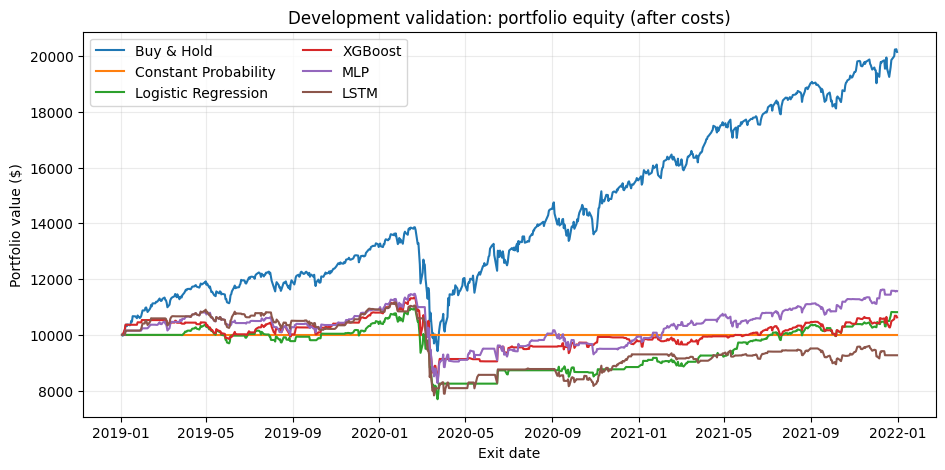

In [2]:
fig, ax = plt.subplots(figsize=(11, 5))
first_entry = pd.to_datetime(performance['first_entry']).min()
initial_capital = json.loads((REPORT / 'config.json').read_text())['initial_capital']
initial = pd.DataFrame(initial_capital, index=[first_entry], columns=equity.columns)
wealth = pd.concat([initial, equity])
for name in wealth.columns:
    ax.plot(wealth.index, wealth[name], label=name, linewidth=1.5)
ax.set(title='Development validation: portfolio equity (after costs)', xlabel='Date', ylabel='Portfolio value ($)')
ax.grid(alpha=.25)
ax.legend(ncol=2)
plt.show()

## Drawdowns

Maximum drawdown is computed against a running peak **including initial equity**. Daily Sharpe is annualized using 252 sessions; serial correlation may make this convention imperfect.

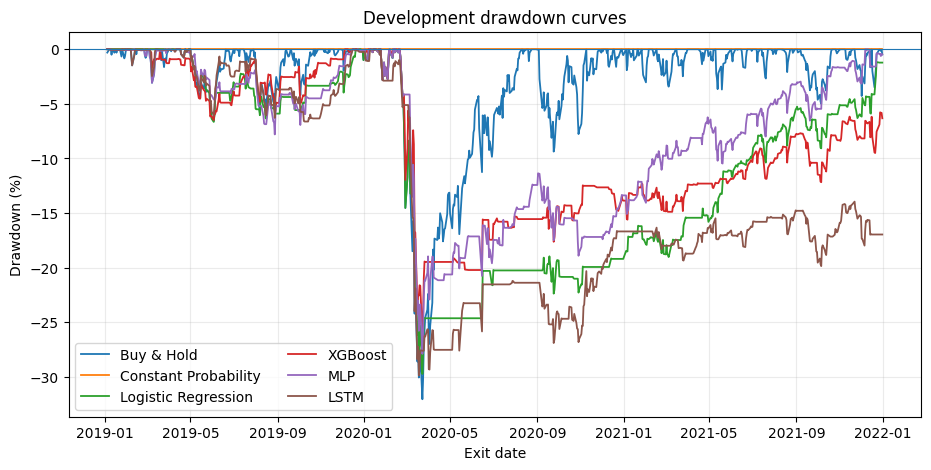

In [3]:
fig, ax = plt.subplots(figsize=(11, 5))
for name in drawdowns.columns:
    ax.plot(drawdowns.index, 100 * drawdowns[name], label=name, linewidth=1.3)
ax.axhline(0, linewidth=0.8)
ax.set(title='Development drawdown curves', xlabel='Exit date', ylabel='Drawdown (%)')
ax.legend(ncol=2)
ax.grid(alpha=.25)
plt.show()

## Performance summary

**Higher Sharpe does not necessarily indicate timing alpha.** Compare CAGR, max drawdown, one-sided turnover, market exposure and costs together. The same threshold is applied to all five model outputs for an initial controlled comparison.

In [4]:
cols = ['strategy','cagr','annualized_volatility','sharpe_ratio','max_drawdown',
        'market_exposure','one_sided_trades','estimated_cost_dollars']
display(performance[cols].sort_values('sharpe_ratio', ascending=False))

,strategy,cagr,annualized_volatility,sharpe_ratio,max_drawdown,market_exposure,one_sided_trades,estimated_cost_dollars
0,Buy & Hold,0.263674,0.195639,1.293982,0.320490,1.000000,1,5.000000
4,MLP,0.049959,0.155313,0.392388,0.278968,0.532450,240,1240.044953
2,Logistic Regression,0.026517,0.140657,0.257296,0.297338,0.418543,180,867.874779
3,XGBoost,0.020536,0.140974,0.215603,0.263249,0.410596,271,1366.088807
5,LSTM,-0.025030,0.142888,-0.104579,0.298595,0.484768,166,797.718409
1,Constant Probability,0.000000,0.000000,NaN,-0.000000,0.000000,0,0.000000


## Inspect individual trades

Read the XGBoost file to check that signal_date < entry_date < exit_date, that the position is held over the next open-to-open interval, and that repeated Long days do **not** pay additional fees.

In [5]:
trades = pd.read_csv(REPORT / 'backtests' / 'xgboost.csv', parse_dates=['exit_date', 'signal_date', 'entry_date']).set_index('exit_date')
display(trades[['signal_date','entry_date','probability','position','turnover','cost_fraction','net_return','equity']].head(20))
assert (trades.signal_date.to_numpy() < trades.entry_date.to_numpy()).all()
assert (trades.entry_date.to_numpy() < trades.index.to_numpy()).all()

,signal_date,entry_date,probability,position,turnover,cost_fraction,net_return,equity
exit_date,,,,,,,,
2019-01-04,2019-01-02,2019-01-03,0.545807,0,0,0.0000,0.000000,10000.000000
2019-01-07,2019-01-03,2019-01-04,0.607108,1,1,0.0005,0.020088,10200.882680
2019-01-08,2019-01-04,2019-01-07,0.570808,1,0,0.0000,0.016344,10367.610307
2019-01-09,2019-01-07,2019-01-08,0.409029,0,1,0.0005,-0.000500,10362.426501
2019-01-10,2019-01-08,2019-01-09,0.429189,0,0,0.0000,0.000000,10362.426501
2019-01-11,2019-01-09,2019-01-10,0.385100,0,0,0.0000,0.000000,10362.426501
2019-01-14,2019-01-10,2019-01-11,0.412738,0,0,0.0000,0.000000,10362.426501
2019-01-15,2019-01-11,2019-01-14,0.424948,0,0,0.0000,0.000000,10362.426501
2019-01-16,2019-01-14,2019-01-15,0.444427,0,0,0.0000,0.000000,10362.426501


## Interpretation limits

1. SPY total-return adjusted-open proxy is not an actual tradable opening price.
2. Costs of 5 bps per trade side are hypothetical; no spread/fill model beyond this approximation.
3. Sharpe and annualized risk metrics are point estimates over a **development** interval.
4. Strong equity performance in 2019–2021 does not guarantee live profitability.
5. The 2022–2026 held-out test must remain closed until all research choices are frozen.

## What happened with the fixed 0.55 rule?

Buy & Hold gained 101.44% cumulatively with annualized Sharpe 1.294. MLP was the strongest active rule by cumulative return (+15.71%, Sharpe 0.392) and held SPY on 53.25% of sessions. Logistic regression gained 8.15%, XGBoost gained 6.27% and LSTM lost 7.30%. All values use the same 755 holding periods and the 5-basis-point fee on each position change.

The prior scored best on forecasting Log Loss but always predicted 54.45%, below the 55% threshold. Its portfolio stayed in cash, earned 0%, and has undefined Sharpe because the daily return has zero variance. Forecast scoring rewards probability estimates on every date. Portfolio returns also depend on the threshold, time invested, size of each realized move and turnover. Maximum drawdown was 27.90% for MLP and 32.05% for Buy & Hold.